# EDA de la estación pluviométrica 35

Estación 35, I.E. Joaquín Vallejo Arbeláez (La Ladera, Medellín), en el mismo punto que la meteorológica 367.
Dos pluviómetros de balancín (`p1`, `p2`), lluvia en mm por minuto, y la columna `calidad` de SIATA.
Periodo: 1 dic 2025 a 30 abr 2026, hora local (UTC-5). El reloj de esta estación ya viene en hora local.

El notebook cubre A1 a A6 del enunciado. Antes de cada gráfico va la pregunta que responde y después la conclusión
con las cifras que salen de las celdas. Se usan las salidas del pipeline (`parte2/salidas/`), que se generan con
`python -m siata.pipeline` desde `parte2/`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats

from siata import datos
from siata.datos import DIR_SALIDAS, RAIZ, ESTACIONES, agregar

sns.set_theme(style="whitegrid", palette="colorblind")
COL = sns.color_palette("colorblind")
FIG = RAIZ / "parte2" / "figuras"
FIG.mkdir(exist_ok=True)
VUELTA = 0.254  # mm por vuelta del balancín (0,01 pulgadas)
PERIODO = "1 dic 2025 - 30 abr 2026, hora local"
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
import warnings
warnings.filterwarnings("ignore", message="obj.round has no effect")  # round() sobre tablas con fechas
MESES = ["", "ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]


def guardar(fig, nombre):
    fig.savefig(FIG / f"04_{nombre}.png", dpi=110, bbox_inches="tight")


def fecha_es(ax):
    """Eje x de fechas con meses en español."""
    ax.xaxis.set_major_formatter(plt.FuncFormatter(
        lambda x, _: (lambda t: f"{t.day} {MESES[t.month]}\n{t.year}")(mdates.num2date(x))))


raw = datos.cargar("35")                                     # CSV tal cual
m = pd.read_parquet(DIR_SALIDAS / "minutal_35.parquet")      # malla minutal regularizada + banderas propias
m367 = pd.read_parquet(DIR_SALIDAS / "minutal_367.parquet")  # misma ubicación, se usa como testigo
horario = pd.read_parquet(DIR_SALIDAS / "horario.parquet")
p = m[["p1", "p2"]]
lluvia = p.mean(axis=1)        # serie de referencia: media de los dos balancines
moja = (p > 0).any(axis=1)     # minuto con lluvia: al menos un balancín dio una vuelta
print(ESTACIONES["35"]["nombre"], "|", len(raw), "filas |", m.index.min(), "a", m.index.max())

I.E. Joaquín Vallejo Arbeláez (La Ladera, Medellín) | 217440 filas | 2025-12-01 00:00:00 a 2026-04-30 23:59:00


## A1. Perfilamiento

¿Qué tipos, rangos, nulos, centinelas y duplicados trae el archivo, y el índice es regular?

In [2]:
print(raw.dtypes.to_string(), "\n")
print("filas:", len(raw), "| minutos esperados:", len(datos.malla("35")))
print("nulos por columna:", raw.isna().sum().to_dict())
print("duplicados (codigo, fecha_hora):", raw.duplicated(["codigo", "fecha_hora"]).sum())
print("índice ordenado:", raw["fecha_hora"].is_monotonic_increasing)
print("pasos entre registros:", raw["fecha_hora"].diff().value_counts().to_dict())
print("marcas con segundos distintos de cero:", int((raw["fecha_hora"].dt.second != 0).sum()))

codigo                 int64
fecha_hora    datetime64[us]
p1                   float64
p2                   float64
calidad                int64 

filas: 217440 | minutos esperados: 217440
nulos por columna: {'codigo': 0, 'fecha_hora': 0, 'p1': 0, 'p2': 0, 'calidad': 0}
duplicados (codigo, fecha_hora): 0
índice ordenado: True
pasos entre registros: {Timedelta('0 days 00:01:00'): 217439}
marcas con segundos distintos de cero: 0


In [3]:
validos = raw[["p1", "p2"]].mask(raw[["p1", "p2"]] == -999)
resumen = validos.describe().T
resumen["centinelas_-999"] = (raw[["p1", "p2"]] == -999).sum()
resumen["valores_distintos"] = validos.nunique()
resumen.round(4)

,count,mean,std,min,25%,50%,75%,max,centinelas_-999,valores_distintos
p1,217433.0,0.0039,0.0482,0.0,0.0,0.0,0.0,2.286,7,10
p2,217433.0,0.0039,0.0488,0.0,0.0,0.0,0.0,2.286,7,10


¿Todos los valores son múltiplos de la vuelta del balancín (0,254 mm)? Esto define la resolución.

In [4]:
vueltas = validos / VUELTA
print("desviación máxima respecto a un múltiplo de 0,254 mm:", float((vueltas - vueltas.round()).abs().max().max()))
conteo = pd.DataFrame({v: vueltas[v].round().value_counts().sort_index() for v in ["p1", "p2"]}).fillna(0).astype(int)
conteo.index = [f"{int(k)} vueltas = {k * VUELTA:.3f} mm" for k in conteo.index]
conteo

desviación máxima respecto a un múltiplo de 0,254 mm: 0.0


,p1,p2
0 vueltas = 0.000 mm,215212,215192
1 vueltas = 0.254 mm,1685,1703
2 vueltas = 0.508 mm,252,252
3 vueltas = 0.762 mm,137,136
4 vueltas = 1.016 mm,67,62
5 vueltas = 1.270 mm,42,48
6 vueltas = 1.524 mm,17,18
7 vueltas = 1.778 mm,10,11
8 vueltas = 2.032 mm,10,8
9 vueltas = 2.286 mm,1,3


¿Cuándo aparecen los centinelas -999, con qué código de calidad y estaba lloviendo alrededor?

In [5]:
cent = raw[(raw["p1"] == -999) | (raw["p2"] == -999)].set_index("fecha_hora")[["p1", "p2", "calidad"]]
for v in ["p1", "p2"]:
    cent[f"{v}_±30min_mm"] = [m[v].loc[t - pd.Timedelta("30min"): t + pd.Timedelta("30min")].sum() for t in cent.index]
cent["lluvia_dia_mm"] = [lluvia.loc[str(t.date())].sum() for t in cent.index]
cent

,p1,p2,calidad,p1_±30min_mm,p2_±30min_mm,lluvia_dia_mm
fecha_hora,,,,,,
2026-01-08 11:26:00,-999.0,-999.0,151,0.0,0.0,0.254
2026-01-08 11:35:00,-999.0,-999.0,151,0.0,0.0,0.254
2026-01-08 11:59:00,-999.0,-999.0,151,0.0,0.0,0.254
2026-01-08 12:01:00,-999.0,-999.0,151,0.0,0.0,0.254
2026-01-08 16:16:00,-999.0,-999.0,151,0.0,0.0,0.254
2026-01-08 16:17:00,-999.0,-999.0,151,0.0,0.0,0.254
2026-03-25 19:46:00,-999.0,-999.0,151,0.0,0.0,0.000


El archivo trae las 217 440 filas esperadas, sin nulos, sin duplicados, ordenado y con paso exacto de
1 minuto (ninguna marca con segundos). p1 y p2 vienen en float64 y `calidad` en entero.

Todos los valores válidos son múltiplos exactos de 0,254 mm (desviación máxima 0,0). Son balancines de 0,01 pulgadas:
la lluvia de un minuto solo puede valer 0, 1, 2, ... vueltas, y el máximo observado es 9 vueltas (2,286 mm). Dos
consecuencias: la intensidad a 1 minuto tiene una resolución de 15,24 mm/h, y un valor que no sea múltiplo de 0,254
sería un error (no hay ninguno).

Hay 7 centinelas -999, siempre en p1 y p2 a la vez y siempre con código 151: seis el 8 ene 2026 entre las 11:26 y las
16:17, y uno el 25 mar 2026 a las 19:46. Ninguno tiene lluvia en ±30 min. No se imputan como cero: -999 dice que el
registrador no leyó el sensor, no que no llovió. Aquí el efecto en los totales sería nulo, pero imputar cero borraría
la falla de la completitud y, en un minuto de tormenta, subestimaría la lluvia. `datos.regularizar` los deja en NaN y
los marca en la columna `centinela`.

## A2. Completitud temporal

Hay dos formas de faltar: que el minuto no llegue o llegue con centinela, y que llegue tarde. El primer dígito 2 de
`calidad` indica dato no obtenido en tiempo real (guía de la red pluviométrica, P-GAA-SIATA-107, Tabla 4, p. 6: códigos 2, 251 y 2512). Para un sistema de
alerta, un dato que llega dos días después es un dato que no estuvo cuando se necesitaba.

In [6]:
falta = p.isna().any(axis=1)
tarde = m["calidad"].astype(str).str.startswith("2")


def rachas(mascara):
    """Inicio, fin y duración en minutos de cada racha de True."""
    grupo = (mascara != mascara.shift()).cumsum()
    t = mascara.index.to_series()[mascara]
    return t.groupby(grupo[mascara]).agg(["min", "max", "size"]).set_axis(["inicio", "fin", "minutos"], axis=1).reset_index(drop=True)


tabla = pd.Series({
    "minutos esperados": len(m),
    "filas recibidas": int(m["presente"].sum()),
    "minutos con centinela -999": int(m["centinela"].sum()),
    "minutos con valor": int((~falta).sum()),
    "completitud (%)": round(100 * (~falta).mean(), 3),
    "minutos que llegaron después (código 2xx)": int(tarde.sum()),
    "completitud en tiempo real (%)": round(100 * (~falta & ~tarde).mean(), 3),
})
print(tabla.to_string(), "\n")
print("rachas de faltantes:\n", rachas(falta).to_string(), "\n")
print("rachas de datos que llegaron después:\n", rachas(tarde).to_string())

minutos esperados                            217440.000
filas recibidas                              217440.000
minutos con centinela -999                        7.000
minutos con valor                            217433.000
completitud (%)                                  99.997
minutos que llegaron después (código 2xx)      2946.000
completitud en tiempo real (%)                   98.642 

rachas de faltantes:
                inicio                 fin  minutos
0 2026-01-08 11:26:00 2026-01-08 11:26:00        1
1 2026-01-08 11:35:00 2026-01-08 11:35:00        1
2 2026-01-08 11:59:00 2026-01-08 11:59:00        1
3 2026-01-08 12:01:00 2026-01-08 12:01:00        1
4 2026-01-08 16:16:00 2026-01-08 16:17:00        2
5 2026-03-25 19:46:00 2026-03-25 19:46:00        1 

rachas de datos que llegaron después:
                inicio                 fin  minutos
0 2025-12-14 09:37:00 2025-12-16 10:40:00     2944
1 2025-12-16 10:51:00 2025-12-16 10:52:00        2


In [7]:
por_mes = pd.DataFrame({"faltantes": falta.groupby(m.index.month).sum(), "llegaron_despues": tarde.groupby(m.index.month).sum()})
por_hora = pd.DataFrame({"faltantes": falta.groupby(m.index.hour).sum(), "llegaron_despues": tarde.groupby(m.index.hour).sum()})
print("por mes (minutos):\n", por_mes.to_string(), "\n")
print("por hora del día (minutos), solo horas con algo:\n", por_hora[por_hora.sum(axis=1) > 0].T.to_string())

por mes (minutos):
             faltantes  llegaron_despues
fecha_hora                             
1                   6                 0
2                   0                 0
3                   1                 0
4                   0                 0
12                  0              2946 

por hora del día (minutos), solo horas con algo:
 fecha_hora         0    1    2    3    4    5    6    7    8    9    10   11   12   13   14   15   16   17   18   19   20   21   22   23
faltantes           0    0    0    0    0    0    0    0    0    0    0    3    1    0    0    0    2    0    0    1    0    0    0    0
llegaron_despues  120  120  120  120  120  120  120  120  120  143  163  120  120  120  120  120  120  120  120  120  120  120  120  120


¿Dónde caen en el calendario los minutos faltantes y los que llegaron tarde? El mapa no interpola nada:
cada celda es una hora y toma el peor estado de sus 60 minutos.

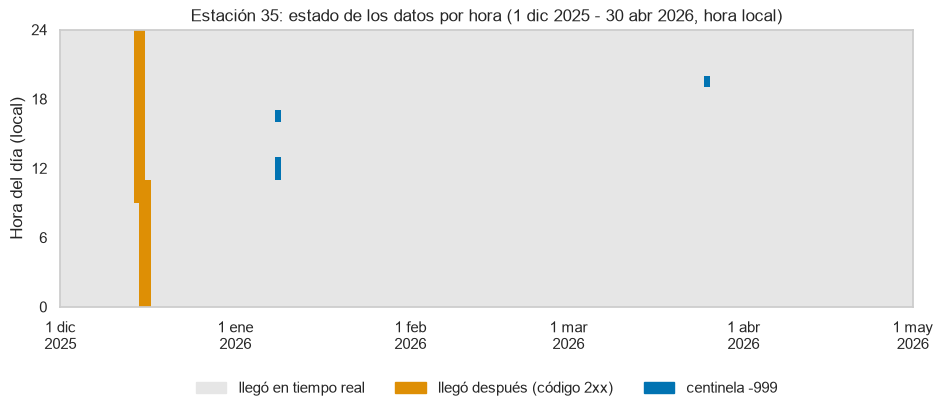

In [8]:
estado = pd.Series(0, index=m.index)
estado[tarde] = 1
estado[falta] = 2
mapa = estado.groupby([m.index.normalize(), m.index.hour]).max().unstack()
dias = mdates.date2num(mapa.index.to_pydatetime())
colores = ["#e6e6e6", COL[1], COL[0]]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.imshow(mapa.T.to_numpy(), aspect="auto", origin="lower", interpolation="nearest", cmap=ListedColormap(colores),
          vmin=0, vmax=2, extent=[dias[0], dias[-1] + 1, 0, 24])
ax.xaxis_date()
ax.grid(False)
fecha_es(ax)
ax.set_yticks(range(0, 25, 6))
ax.set_ylabel("Hora del día (local)")
ax.set_title(f"Estación 35: estado de los datos por hora ({PERIODO})")
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(colores, ["llegó en tiempo real", "llegó después (código 2xx)", "centinela -999"])],
          loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
guardar(fig, "estado_datos")
plt.show()

Contando minutos con valor, la completitud es 99,997 %: solo faltan los 7 minutos con centinela, en seis rachas de 1 o
2 minutos (enero y marzo, entre las 11 y las 19 h). No hay huecos sin fila.

El problema está en otro lado: 2946 minutos llegaron después (código 2xx). Son una racha de 2944 minutos, del 14 dic
2025 a las 09:37 al 16 dic a las 10:40 (49 h), y 2 minutos el 16 dic a las 10:51 y 10:52. Contando solo lo que llegó
en tiempo real, la completitud baja a 98,64 %. Para el archivo histórico esos datos sirven; para la alerta temprana,
la estación estuvo 49 h sin reportar y un indicador que cuenta filas no lo muestra. Por hora del día la racha es plana
(120 minutos en cada hora, algo más a las 9 y 10 h, donde empieza y termina): es una sola falla continua, no un patrón
del día ni del mes.

## A3. Distribución de las variables

### Intermitencia

¿Qué fracción del tiempo llueve? Se cuenta un minuto (hora, día) con lluvia si al menos un balancín
registró una vuelta.

In [9]:
H = p.resample("h").sum(min_count=1)
D = p.resample("D").sum(min_count=1)
moja_h, moja_d = (H > 0).any(axis=1), (D > 0).any(axis=1)
print(f"minutos con lluvia: {moja.sum()} de {len(m)} ({100 * moja.mean():.2f} %)")
print(f"horas con lluvia:   {moja_h.sum()} de {len(H)} ({100 * moja_h.mean():.2f} %)")
print(f"días con lluvia:    {moja_d.sum()} de {len(D)} ({100 * moja_d.mean():.2f} %); días con 1 mm o más: {(D.mean(axis=1) >= 1).sum()}")
# concentración: qué fracción de los minutos con lluvia aporta la mitad del total
orden = lluvia[moja].sort_values(ascending=False)
mitad = (orden.cumsum() <= orden.sum() / 2).sum() + 1
print(f"la mitad de la lluvia cae en {mitad} minutos: {100 * mitad / moja.sum():.1f} % de los minutos con lluvia, {100 * mitad / len(m):.2f} % del periodo")

minutos con lluvia: 3119 de 217440 (1.43 %)
horas con lluvia:   356 de 3624 (9.82 %)
días con lluvia:    96 de 151 (63.58 %); días con 1 mm o más: 79
la mitad de la lluvia cae en 573 minutos: 18.4 % de los minutos con lluvia, 0.26 % del periodo


Cuando llueve, ¿con qué intensidad? Solo minutos y horas con lluvia, eje vertical en escala logarítmica
porque las intensidades bajas dominan.

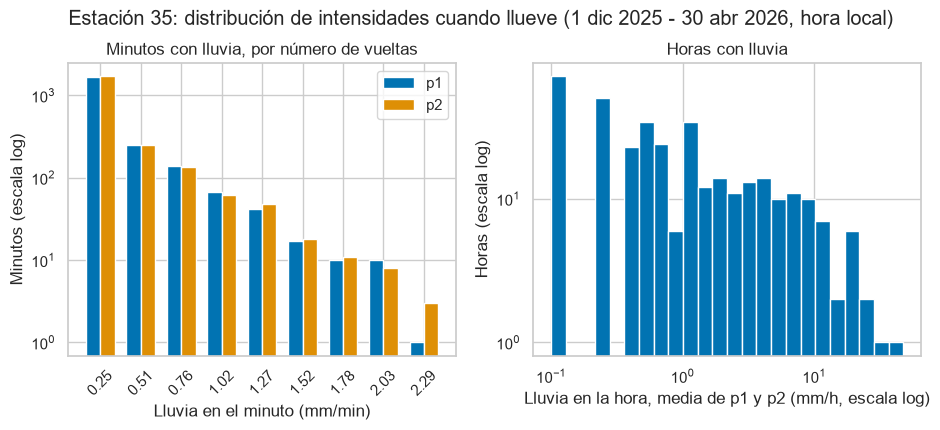

p1: 2221 minutos con lluvia, 75.9 % con una sola vuelta
p2: 2241 minutos con lluvia, 76.0 % con una sola vuelta
percentiles de la lluvia horaria en horas con lluvia (mm/h):
0.25     0.254
0.50     0.572
0.75     2.159
0.90     6.668
0.99    21.977
1.00    43.180


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
k = np.arange(1, 10)
for i, v in enumerate(["p1", "p2"]):
    n = (p[v] / VUELTA).round().value_counts().reindex(k, fill_value=0)
    ax[0].bar(k * VUELTA + (i - 0.5) * 0.09, n, width=0.09, color=COL[i], label=v)
ax[0].set_yscale("log")
ax[0].set_xticks(k * VUELTA, [f"{x:.2f}" for x in k * VUELTA], rotation=45)
ax[0].set_xlabel("Lluvia en el minuto (mm/min)")
ax[0].set_ylabel("Minutos (escala log)")
ax[0].set_title("Minutos con lluvia, por número de vueltas")
ax[0].legend()
hh = H.mean(axis=1)[moja_h]
bordes = np.logspace(np.log10(0.1), np.log10(hh.max() * 1.1), 25)
ax[1].hist(hh, bins=bordes, color=COL[0])
ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_xlabel("Lluvia en la hora, media de p1 y p2 (mm/h, escala log)")
ax[1].set_ylabel("Horas (escala log)")
ax[1].set_title("Horas con lluvia")
fig.suptitle(f"Estación 35: distribución de intensidades cuando llueve ({PERIODO})", y=1.02)
plt.show()
for v in ["p1", "p2"]:
    print(f"{v}: {(p[v] > 0).sum()} minutos con lluvia, {100 * (p[v] == VUELTA).sum() / (p[v] > 0).sum():.1f} % con una sola vuelta")
print("percentiles de la lluvia horaria en horas con lluvia (mm/h):")
print(hh.quantile([0.25, 0.5, 0.75, 0.9, 0.99, 1]).round(3).to_string())

La lluvia es muy intermitente: llueve en el 1,43 % de los minutos (3119), en el 9,82 % de las horas (356)
y en el 63,6 % de los días (96 de 151; 79 con 1 mm o más). Además está concentrada: la mitad del total cae en 573
minutos, el 0,26 % del periodo.

Cuando llueve, domina la vuelta suelta: el 75,9 % de los minutos con lluvia de p1 (76,0 % en p2) tiene una sola
vuelta. En las horas con lluvia la mediana es 0,57 mm/h, el percentil 90 es 6,67 mm/h, el 99 es 21,98 mm/h y el
máximo 43,18 mm/h. Las barras vacías a la izquierda del histograma horario no son huecos: con balancines de 0,254 mm,
la media de p1 y p2 en una hora solo puede valer múltiplos de 0,127 mm.

En el panel minutal, los minutos con 8 vueltas (10 en p1) son tantos como los de 7 (10); la mitad de los de 8 en p1 son las
ráfagas sospechosas de A5. Fuera de ellas, los minutos de 8 vueltas bajan a 5 en cada balancín, la mitad de los de 7.

Implicación para la Tarea B: una serie así no se modela bien con un modelo continuo de error gaussiano; conviene
separar la ocurrencia (llueve o no) de la cantidad.

¿Cambia la intensidad horaria según el mes o la hora del día? Boxplots de la lluvia horaria solo en horas
con lluvia (con todas las horas, la caja sería un cero).

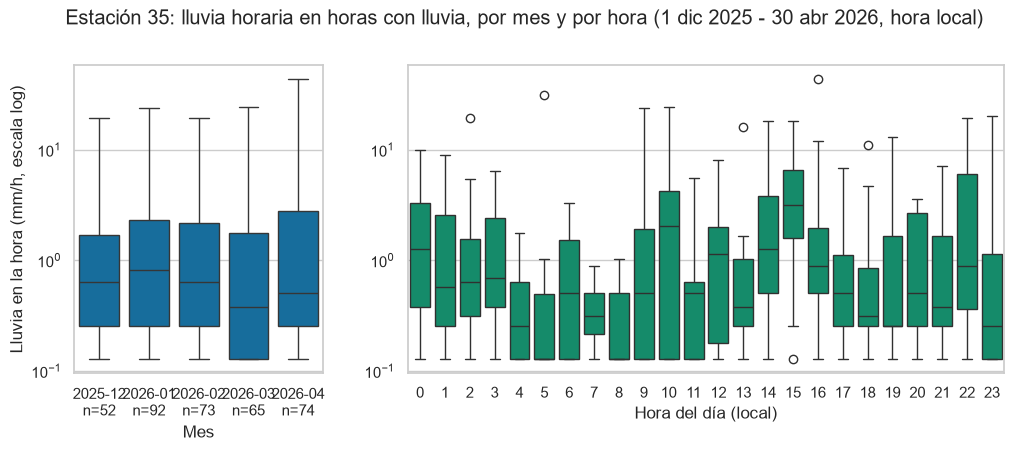

horas con lluvia y mediana (mm/h) por mes:
 mes     2025-12  2026-01  2026-02  2026-03  2026-04
size     52.000   92.000   73.000   65.000   74.000
median    0.635    0.826    0.635    0.381    0.508

por hora del día:
 hora       0      1      2     3      4      5     6     7     8      9     10    11    12     13     14     15     16     17     18     19     20     21     22     23
size    17.00  20.00  19.00  16.0  17.00  11.00  7.00  8.00  5.00  11.00  9.00  9.00  7.00  13.00  25.00  27.00  35.00  26.00  14.00  11.00  10.00  13.00  11.00  15.00
median   1.27   0.57   0.64   0.7   0.25   0.13  0.51  0.32  0.13   0.51  2.03  0.51  1.14   0.38   1.27   3.18   0.89   0.51   0.32   0.25   0.51   0.38   0.89   0.25


In [11]:
hh_df = pd.DataFrame({"mm_h": hh, "mes": hh.index.strftime("%Y-%m"), "hora": hh.index.hour})
fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2.4]})
sns.boxplot(data=hh_df, x="mes", y="mm_h", ax=ax[0], color=COL[0], log_scale=True)
ax[0].set_xlabel("Mes")
ax[0].set_ylabel("Lluvia en la hora (mm/h, escala log)")
n_mes = hh_df.groupby("mes").size()
ax[0].set_xticks(range(len(n_mes)), [f"{t}\nn={n}" for t, n in n_mes.items()])
sns.boxplot(data=hh_df, x="hora", y="mm_h", ax=ax[1], color=COL[2], log_scale=True)
ax[1].set_xlabel("Hora del día (local)")
ax[1].set_ylabel("")
fig.suptitle(f"Estación 35: lluvia horaria en horas con lluvia, por mes y por hora ({PERIODO})", y=1.02)
plt.show()
print("horas con lluvia y mediana (mm/h) por mes:\n", hh_df.groupby("mes")["mm_h"].agg(["size", "median"]).round(3).T.to_string())
print("\npor hora del día:\n", hh_df.groupby("hora")["mm_h"].agg(["size", "median"]).round(2).T.to_string())

Entre meses la mediana de las horas con lluvia cambia poco (de 0,38 mm/h en marzo a 0,83 mm/h en enero) y
las cajas se solapan: ningún mes tiene lluvias horarias mucho más intensas. Por hora del día sí hay diferencia: la
mediana más alta es la de las 15 h (3,18 mm/h, 27 horas), lo que coincide con el ciclo diurno de A4. Hay que leerlo
con cuidado: cada caja horaria tiene entre 5 y 35 horas, así que una diferencia entre horas vecinas (por ejemplo, la
mediana de 2,03 mm/h a las 10 h, con 9 horas) puede ser de una sola tormenta.

### La columna `calidad`

¿Qué códigos hay, con qué frecuencia y con qué valores de p1 y p2 aparecen?

In [12]:
cod = m["calidad"]
freq = cod.value_counts().to_frame("minutos")
freq["%"] = (100 * freq.minutos / len(m)).round(4)
print(freq.to_string(), "\n")
cond = pd.Series(np.select([m.centinela, (p.p1 == 0) & (p.p2 == 0), (p.p1 > 0) & (p.p2 > 0), (p.p1 > 0) & (p.p2 == 0)],
                           ["centinela -999", "seco (los dos en 0)", "los dos > 0", "solo p1 > 0"], "solo p2 > 0"), index=m.index)
pd.crosstab(cod, cond)

         minutos        %
calidad                  
1         214388  98.5964
2           2944   1.3539
1512          54   0.0248
1511          43   0.0198
151            9   0.0041
251            1   0.0005
2512           1   0.0005 



col_0,centinela -999,los dos > 0,seco (los dos en 0),solo p1 > 0,solo p2 > 0
calidad,,,,,
1,0,1338,211374,834,842
2,0,2,2940,1,1
151,7,2,0,0,0
251,0,1,0,0,0
1511,0,0,0,43,0
1512,0,0,0,0,54
2512,0,0,0,0,1


¿1511 y 1512 marcan todos los minutos en que solo un balancín registró, o solo algunos? ¿Cuáles?

In [13]:
for codigo, solo, otro in [(1511, "solo p1 > 0", "p2"), (1512, "solo p2 > 0", "p1")]:
    marcado = cod == codigo
    candidatos = cond == solo
    otro_seco = p[otro].rolling(3, center=True, min_periods=1).sum() == 0  # el otro balancín sin vueltas en ±1 min
    print(f"{codigo}: {marcado.sum()} de {candidatos.sum()} minutos '{solo}' ({100 * marcado.sum() / candidatos.sum():.1f} %); "
          f"el otro balancín seco en ±1 min: {100 * otro_seco[marcado].mean():.0f} % de los marcados frente a "
          f"{100 * otro_seco[candidatos & ~marcado].mean():.0f} % de los no marcados")
print("\nminutos con 151, 251 y 2512:")
print(m.loc[cod.isin([151, 251, 2512]), ["p1", "p2", "calidad", "centinela"]].to_string())

1511: 43 de 878 minutos 'solo p1 > 0' (4.9 %); el otro balancín seco en ±1 min: 91 % de los marcados frente a 41 % de los no marcados
1512: 54 de 898 minutos 'solo p2 > 0' (6.0 %); el otro balancín seco en ±1 min: 91 % de los marcados frente a 41 % de los no marcados

minutos con 151, 251 y 2512:
                        p1     p2  calidad  centinela
fecha_hora                                           
2025-12-16 10:51:00  2.032  1.778      251      False
2025-12-16 10:52:00  0.000  0.254     2512      False
2026-01-08 11:26:00    NaN    NaN      151       True
2026-01-08 11:35:00    NaN    NaN      151       True
2026-01-08 11:59:00    NaN    NaN      151       True
2026-01-08 12:01:00    NaN    NaN      151       True
2026-01-08 16:16:00    NaN    NaN      151       True
2026-01-08 16:17:00    NaN    NaN      151       True
2026-01-16 11:10:00  2.032  1.016      151      False
2026-02-18 12:17:00  0.254  0.254      151      False
2026-03-25 19:46:00    NaN    NaN      151       True


¿Cómo evolucionan los códigos distintos de 1 en el tiempo?

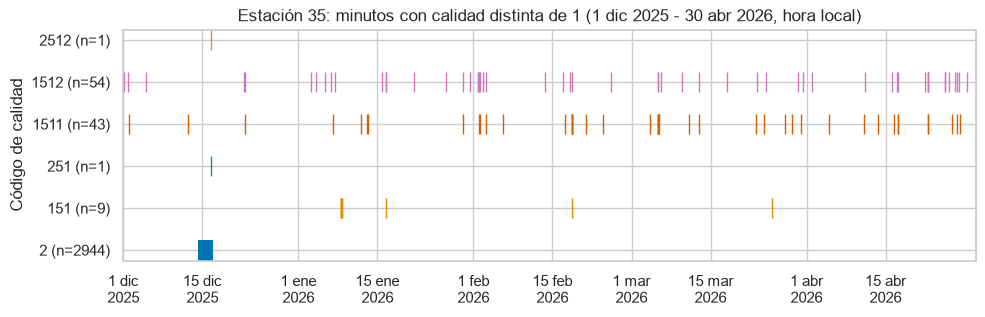

meses con 1511 / 1512: row_0    2025-12  2026-01  2026-02  2026-03  2026-04
calidad                                             
1511           3        5       11       13       11
1512           5       12       11       10       16


In [14]:
otros = cod[cod != 1]
orden_cod = sorted(otros.unique())
fig, ax = plt.subplots(figsize=(11, 3))
for i, c in enumerate(orden_cod):
    t = otros.index[otros == c]
    ax.plot(t, np.full(len(t), i), "|", ms=14, color=COL[i % len(COL)])
ax.set_yticks(range(len(orden_cod)), [f"{c} (n={(otros == c).sum()})" for c in orden_cod])
ax.set_ylabel("Código de calidad")
ax.set_xlim(m.index.min(), m.index.max())
fecha_es(ax)
ax.set_title(f"Estación 35: minutos con calidad distinta de 1 ({PERIODO})")
plt.show()
print("meses con 1511 / 1512:", pd.crosstab(otros.index.strftime("%Y-%m"), otros).loc[:, [1511, 1512]].T.to_string())

¿Coincide la `calidad` de SIATA con el control propio del paquete (`siata.calidad.evaluar`)?

In [15]:
print(pd.crosstab(cod, m["b_registro"], margins=True).to_string(), "\n")
per = pd.read_csv(RAIZ / "parte2" / "resultados" / "indicadores_periodo.csv").query("codigo == 35")
print(per[["variable", "kappa", "falsos_confiables", "dudosos_que_pasan", "semaforo_kappa"]].round(3).to_string(index=False))

b_registro       1    3  9     All
calidad                           
1           214153  235  0  214388
2             2944    0  0    2944
151              1    1  7       9
251              1    0  0       1
1511            35    8  0      43
1512            51    3  0      54
2512             1    0  0       1
All         217186  247  7  217440 

variable  kappa  falsos_confiables  dudosos_que_pasan semaforo_kappa
      p1  0.068              0.001              0.881        crítico
      p2  0.068              0.001              0.881        crítico


El 98,60 % de los minutos tiene código 1 y el 1,35 % código 2; los otros 108 minutos se
reparten en 151, 251, 1511, 1512 y 2512. Lo siguiente se infiere de los datos (el diccionario oficial está en la guía de la red pluviométrica y el contraste en el notebook 07):

- 1511 aparece solo con p1 > 0 y p2 = 0, y 1512 solo con p1 = 0 y p2 > 0, sin excepción (43 y 54 minutos). Esto
  precisa lo que se sabía ("p1 > p2"): cuando los dos registran, aunque difieran, el código es 1. Pero no marcan todos
  esos minutos, solo el 4,9 % y el 6,0 %. Los marcados son sobre todo vueltas aisladas: en el 91 % el otro balancín no
  tuvo vueltas en ±1 min, frente al 41 % de los no marcados. Parece una regla de "un solo balancín, sin vecinos".
- 151 (dudoso) marca los 7 centinelas y 2 minutos más, y esos 2 caen en los episodios de ráfaga de A5 (16 ene a las 11:10, en la ráfaga, y 18 feb a las 12:17, diez minutos antes).
- 251 y 2512 tienen la misma terminación que 151 y 1512 con primer dígito 2 (no tiempo real) y caen en la ráfaga del
  16 dic, al final del periodo con código 2.
- 2 es el dato que llegó después (A2).

1511 y 1512 aparecen en todos los meses (1511 va de 3 minutos en diciembre a 13 en marzo; 1512, de 5 en diciembre a 16 en
abril).

El control propio y la `calidad` de SIATA casi no coinciden: kappa = 0,068 (crítico). De lo que SIATA marca dudoso, el
88,1 % pasa el control propio, y de los 254 minutos que el control propio no da por buenos, 235 tienen código 1. Miran
cosas distintas: SIATA marca minutos con un solo balancín; el control propio marca horas en que los dos difieren en más
de dos vueltas y más del 10 % de la lluvia de la hora (A5). `calidad` no sirve como único filtro.

### Eventos de lluvia

Criterio: un evento es un conjunto de minutos con lluvia separados del siguiente por al menos 2 h secas (120 minutos
seguidos sin vueltas en ningún balancín). Es un criterio común en hidrología urbana; con 1 h salen más eventos, con
6 h menos. El acumulado y la intensidad usan la media de p1 y p2. La intensidad máxima en 10 min se reporta en mm/h
(acumulado de 10 min por 6). El primer evento empieza el 1 dic a las 00:00 con lluvia en curso: queda recortado.

In [16]:
def eventos(lluvia, moja, seco_min=120):
    t = lluvia.index[moja].to_series()
    eid = (t.diff() > pd.Timedelta(minutes=seco_min)).cumsum()  # > 120 min entre vueltas = al menos 120 min secos
    r10 = lluvia.rolling(10, min_periods=1).sum()
    filas = []
    for _, g in t.groupby(eid):
        a, b = g.iloc[0], g.iloc[-1]
        filas.append({"inicio": a, "fin": b, "duracion_min": int((b - a) / pd.Timedelta("1min")) + 1,
                      "acumulado_mm": lluvia.loc[a:b].sum(), "p1_mm": p["p1"].loc[a:b].sum(), "p2_mm": p["p2"].loc[a:b].sum(),
                      "imax10_mm_h": 6 * r10.loc[a: b + pd.Timedelta("9min")].max(), "max_1min_mm": p.loc[a:b].max().max()})
    return pd.DataFrame(filas)


ev = eventos(lluvia, moja)
print("eventos:", len(ev), "| con 1 mm o más:", (ev.acumulado_mm >= 1).sum(), "| con 5 mm o más:", (ev.acumulado_mm >= 5).sum(),
      "| de una sola vuelta (0,127 mm):", (ev.acumulado_mm <= VUELTA / 2 + 1e-9).sum())
print("\nresumen de eventos con 1 mm o más:")
print(ev[ev.acumulado_mm >= 1][["duracion_min", "acumulado_mm", "imax10_mm_h"]].describe().round(2).to_string())
for s in (1, 6):  # sensibilidad al criterio
    print(f"con {s} h secas de separación: {len(eventos(lluvia, moja, 60 * s))} eventos")

eventos: 150 | con 1 mm o más: 91 | con 5 mm o más: 49 | de una sola vuelta (0,127 mm): 27

resumen de eventos con 1 mm o más:
       duracion_min  acumulado_mm  imax10_mm_h
count         91.00         91.00        91.00
mean         136.79          9.15        23.23
std          111.66          9.39        22.05
min            2.00          1.02         1.52
25%           42.00          2.67         6.48
50%          119.00          5.59        14.48
75%          192.00         12.19        36.96
max          502.00         43.56       100.58
con 1 h secas de separación: 188 eventos


con 6 h secas de separación: 113 eventos


In [17]:
ev.sort_values("acumulado_mm", ascending=False).head(10).round(2)

,inicio,fin,duracion_min,acumulado_mm,p1_mm,p2_mm,imax10_mm_h,max_1min_mm
116,2026-04-03 16:02:00,2026-04-03 17:16:00,75,43.56,43.43,43.69,96.77,2.29
51,2026-01-26 22:12:00,2026-01-27 02:21:00,250,37.08,36.83,37.34,47.24,1.27
127,2026-04-16 01:45:00,2026-04-16 07:33:00,349,36.32,34.54,38.10,83.82,2.03
65,2026-02-06 00:55:00,2026-02-06 07:08:00,374,35.56,35.81,35.31,58.67,1.52
37,2026-01-12 09:07:00,2026-01-12 11:21:00,135,28.96,29.21,28.70,44.20,1.02
105,2026-03-27 09:53:00,2026-03-27 13:14:00,202,28.07,27.69,28.45,100.58,2.29
129,2026-04-16 19:46:00,2026-04-17 01:27:00,342,25.40,26.92,23.88,15.24,0.51
0,2025-12-01 00:00:00,2025-12-01 04:03:00,244,22.61,21.34,23.88,28.19,1.02
86,2026-03-05 13:58:00,2026-03-05 15:21:00,84,22.35,22.61,22.10,78.49,2.03
145,2026-04-27 14:47:00,2026-04-27 17:12:00,146,21.08,21.08,21.08,57.15,1.52


Con 2 h secas de separación salen 150 eventos: 91 de 1 mm o más y 49 de 5 mm o más (el mismo número que usa el análisis lluvia-nivel del notebook 05, con la misma separación de 2 h; el notebook 02 separa con 1 h y obtiene 47). 27 son una sola vuelta (0,127 mm de media) y se pueden tratar como
llovizna o ruido. El criterio pesa: con 1 h salen 188 eventos y con 6 h, 113, así que cualquier conteo de eventos
debe decir qué separación usó.

En los eventos de 1 mm o más, la mediana dura 119 min, acumula 5,59 mm y tiene una intensidad máxima en 10 min de
14,5 mm/h. El mayor evento fue el 3 abr 2026, de 16:02 a 17:16: 43,56 mm en 75 min, con 96,8 mm/h de intensidad máxima
en 10 min. La intensidad máxima en 10 min más alta del periodo es la del 27 mar 2026 (100,6 mm/h). El primer evento
(1 dic, 22,6 mm) empezó antes del periodo y está recortado. Cuatro de los 91 eventos de 1 mm o más son las ráfagas
sospechosas de A5 (de 2,03 a 2,67 mm cada uno).

## A4. Ciclos, estacionalidad y tendencia

### Ciclo diurno

¿A qué hora llueve? Se separan dos cosas: la frecuencia (porcentaje de minutos con lluvia en cada hora) y
la cantidad (lluvia media por hora del día en todo el periodo). Si la lluvia fuera convectiva de la tarde, las dos
subirían después del mediodía.

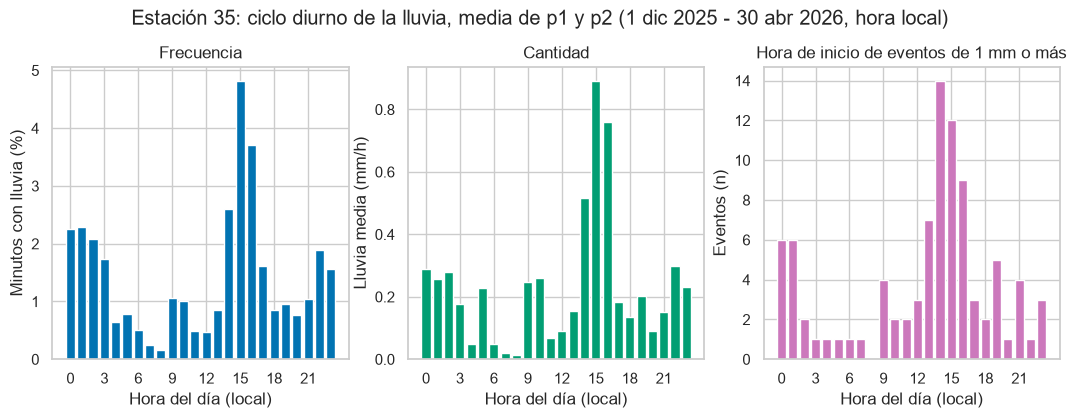

fecha_hora                0     1     2     3     4     5     6     7     8     9     10    11    12    13    14     15     16    17    18    19    20    21    22    23
pct_minutos_con_lluvia  2.25  2.30  2.09  1.74  0.64  0.78  0.51  0.25  0.17  1.06  1.02  0.49  0.46  0.85  2.59   4.82   3.71  1.62  0.86  0.96  0.77  1.04  1.89  1.56
mm_por_hora_media       0.29  0.26  0.28  0.18  0.05  0.23  0.05  0.02  0.01  0.25  0.26  0.07  0.09  0.16  0.52   0.89   0.76  0.18  0.14  0.20  0.09  0.15  0.30  0.23
pct_del_total           5.14  4.55  4.94  3.13  0.89  4.02  0.85  0.36  0.22  4.36  4.58  1.21  1.62  2.75  9.15  15.79  13.44  3.26  2.41  3.60  1.59  2.69  5.30  4.12


In [18]:
hora = m.index.hour
ciclo = pd.DataFrame({"pct_minutos_con_lluvia": 100 * moja.groupby(hora).mean(),
                      "mm_por_hora_media": lluvia.groupby(hora).sum() / len(D),
                      "pct_del_total": 100 * lluvia.groupby(hora).sum() / lluvia.sum()})
grandes = ev[ev.acumulado_mm >= 1]
inicio_h = grandes.inicio.dt.hour.value_counts().reindex(range(24), fill_value=0)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].bar(ciclo.index, ciclo.pct_minutos_con_lluvia, color=COL[0])
ax[0].set_ylabel("Minutos con lluvia (%)")
ax[0].set_title("Frecuencia")
ax[1].bar(ciclo.index, ciclo.mm_por_hora_media, color=COL[2])
ax[1].set_ylabel("Lluvia media (mm/h)")
ax[1].set_title("Cantidad")
ax[2].bar(inicio_h.index, inicio_h, color=COL[4])
ax[2].set_ylabel("Eventos (n)")
ax[2].set_title("Hora de inicio de eventos de 1 mm o más")
for a in ax:
    a.set_xlabel("Hora del día (local)")
    a.set_xticks(range(0, 24, 3))
fig.suptitle(f"Estación 35: ciclo diurno de la lluvia, media de p1 y p2 ({PERIODO})", y=1.03)
guardar(fig, "ciclo_diurno")
plt.show()
print(ciclo.round(2).T.to_string())

¿El máximo de la tarde es de muchos días o de unas pocas tormentas? Se repite el cálculo quitando los 5
días más lluviosos.

In [19]:
tarde_h = (hora >= 14) & (hora <= 16)
print(f"lluvia de 14 a 16 h: {100 * lluvia[tarde_h].sum() / lluvia.sum():.1f} % del total, en {np.mean(np.isin(hora, [14, 15, 16])) * 100:.1f} % de las horas")
dias_tarde = lluvia[tarde_h].resample("D").sum()
print("días distintos con lluvia entre 14 y 16 h:", int((dias_tarde > 0).sum()), "| con 1 mm o más:", int((dias_tarde >= 1).sum()))
top5 = D.mean(axis=1).nlargest(5)
print("5 días más lluviosos (mm):", {str(k.date()): round(v, 1) for k, v in top5.items()})
sin_top = lluvia[~m.index.normalize().isin(top5.index)]
pct_sin = 100 * sin_top.groupby(sin_top.index.hour).sum() / sin_top.sum()
print("sin esos 5 días, % del total por hora (las 6 mayores):", pct_sin.nlargest(6).round(1).to_dict())
noche = np.isin(hora, [22, 23, 0, 1, 2])
print(f"lluvia de 22 a 02 h: {100 * lluvia[noche].sum() / lluvia.sum():.1f} % del total")
print("horas de inicio más frecuentes (eventos de 1 mm o más):", inicio_h.nlargest(4).to_dict(), "| de", len(grandes), "eventos,",
      int(inicio_h.loc[13:17].sum()), "empiezan entre las 13 y las 17 h")

lluvia de 14 a 16 h: 38.4 % del total, en 12.5 % de las horas
días distintos con lluvia entre 14 y 16 h: 52 | con 1 mm o más: 40
5 días más lluviosos (mm): {'2026-04-16': 56.3, '2026-01-12': 50.0, '2026-04-03': 43.6, '2026-02-06': 35.6, '2026-01-26': 30.6}
sin esos 5 días, % del total por hora (las 6 mayores): {15: 20.3, 14: 12.3, 16: 9.1, 0: 6.7, 10: 5.4, 22: 5.1}
lluvia de 22 a 02 h: 24.1 % del total
horas de inicio más frecuentes (eventos de 1 mm o más): {14: 14, 15: 12, 16: 9, 13: 7} | de 91 eventos, 45 empiezan entre las 13 y las 17 h


Hay un ciclo diurno claro y es bimodal. El máximo principal está en la tarde: de 14 a 16 h cae el 38,4 % de
la lluvia en el 12,5 % de las horas. Ahí también están el máximo de frecuencia (el 4,82 % de los minutos de las 15 h
tiene lluvia) y el de inicios de eventos de 1 mm o más (35 de 91 empiezan entre las 14 y las 16 h). No depende de unas
pocas tormentas: hubo lluvia en esa franja en 52 días distintos (40 con 1 mm o más) y, sin los 5 días más lluviosos,
las 15 h siguen siendo la hora con más lluvia (20,3 % del total). Hay un segundo máximo nocturno: de 22 a 02 h cae el
24,1 %. El mínimo está entre las 6 y las 8 h.

Un máximo en la tarde es compatible con lluvia convectiva por el calentamiento del día, pero con solo lluvia no se
puede afirmar el mecanismo; habría que cruzarlo con la temperatura y la humedad de la 367 (notebook comparativo).

### Ciclo semanal

¿Llueve distinto según el día de la semana? No hay razón física para un ciclo semanal en la lluvia; se
revisa para descartarlo. Prueba de Kruskal-Wallis sobre los totales diarios (21 o 22 días por grupo).

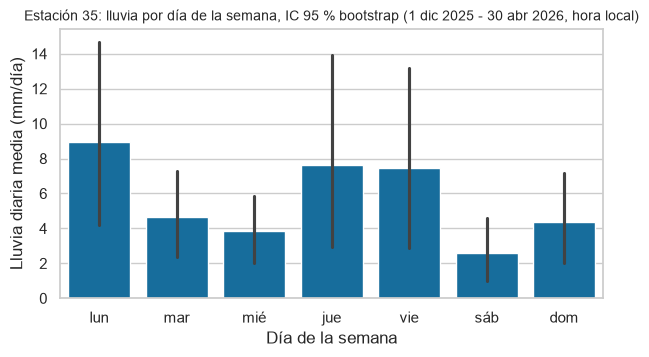

Kruskal-Wallis H = 3.23, p = 0.780
        lun    mar    mié    jue    vie    sáb    dom
size  22.00  22.00  22.00  22.00  21.00  21.00  21.00
mean   8.95   4.64   3.86   7.63   7.44   2.57   4.35


In [20]:
dd = pd.DataFrame({"mm_dia": D.mean(axis=1), "dia": D.index.day_of_week})
nombres = DIAS
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(data=dd, x="dia", y="mm_dia", ax=ax, color=COL[0], errorbar=("ci", 95), seed=0)
ax.set_xticks(range(7), nombres)
ax.set_xlabel("Día de la semana")
ax.set_ylabel("Lluvia diaria media (mm/día)")
ax.set_title(f"Estación 35: lluvia por día de la semana, IC 95 % bootstrap ({PERIODO})", fontsize=10)
plt.show()
kw = stats.kruskal(*[g.mm_dia for _, g in dd.groupby("dia")])
print(f"Kruskal-Wallis H = {kw.statistic:.2f}, p = {kw.pvalue:.3f}")
print(dd.groupby("dia").mm_dia.agg(["size", "mean"]).set_axis(nombres).round(2).T.to_string())

No hay ciclo semanal. Las medias diarias van de 2,57 mm (sábado) a 8,95 mm (lunes), pero los intervalos de
confianza se solapan y Kruskal-Wallis da p = 0,78. Con 21 o 22 días por grupo, dos o tres tormentas mueven la media de
un día de la semana. Si apareciera un ciclo semanal en la lluvia habría que sospechar del proceso (por ejemplo,
mantenimientos en días fijos), no de la atmósfera.

### Estacionalidad y tendencia

¿Cómo se reparte la lluvia en los cinco meses? Totales diarios con media móvil de 7 días y totales
mensuales. No se hace una descomposición STL: la serie diaria es intermitente (más de un tercio de los días son
secos) y cinco meses no cubren un ciclo anual, así que la componente estacional no se puede separar de la variación
de este año en particular.

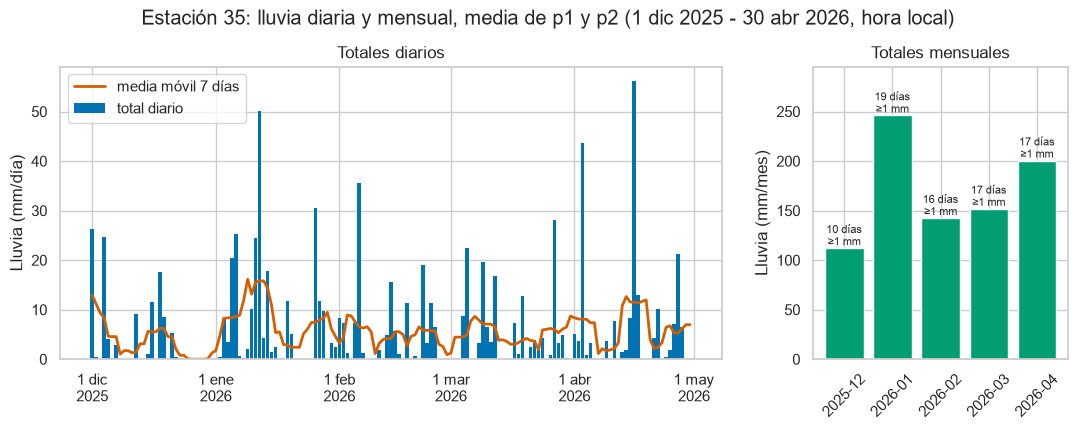

            total_mm  dias_con_lluvia  dias_1mm_o_mas  max_diario_mm  p1_mm  p2_mm
fecha_hora                                                                        
2025-12        112.1               13              10           26.3  109.2  115.1
2026-01        246.1               23              19           50.0  247.4  244.9
2026-02        142.5               18              16           35.6  141.5  143.5
2026-03        151.9               21              17           28.1  151.1  152.7
2026-04        200.5               21              17           56.3  198.9  202.2

días secos: 55 de 151 (36 %)
rachas secas más largas:
     inicio        fin  dias
2025-12-23 2026-01-01    10
2026-02-26 2026-03-03     6
2025-12-08 2025-12-11     4


In [21]:
dm = D.mean(axis=1)
mes = pd.DataFrame({"total_mm": dm.resample("MS").sum(), "dias_con_lluvia": (dm > 0).resample("MS").sum(),
                    "dias_1mm_o_mas": (dm >= 1).resample("MS").sum(), "max_diario_mm": dm.resample("MS").max(),
                    "p1_mm": D["p1"].resample("MS").sum(), "p2_mm": D["p2"].resample("MS").sum()})
mes.index = mes.index.strftime("%Y-%m")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2.6, 1]})
ax[0].bar(dm.index, dm, width=0.9, color=COL[0], linewidth=0, label="total diario")
ax[0].plot(dm.rolling(7, center=True, min_periods=4).mean(), color=COL[3], lw=2, label="media móvil 7 días")
ax[0].set_ylabel("Lluvia (mm/día)")
fecha_es(ax[0])
ax[0].legend()
ax[0].set_title("Totales diarios")
ax[1].bar(mes.index, mes.total_mm, color=COL[2])
for i, (t, n) in enumerate(zip(mes.total_mm, mes.dias_1mm_o_mas)):
    ax[1].text(i, t + 3, f"{n} días\n≥1 mm", ha="center", fontsize=8)
ax[1].set_ylim(0, mes.total_mm.max() * 1.2)
ax[1].set_ylabel("Lluvia (mm/mes)")
ax[1].set_title("Totales mensuales")
ax[1].tick_params(axis="x", rotation=45)
fig.suptitle(f"Estación 35: lluvia diaria y mensual, media de p1 y p2 ({PERIODO})", y=1.03)
plt.show()
print(mes.round(1).to_string())
print(f"\ndías secos: {(dm == 0).sum()} de {len(dm)} ({100 * (dm == 0).mean():.0f} %)")
secas = rachas(dm == 0).rename(columns={"minutos": "dias"})
print("rachas secas más largas:\n", secas.nlargest(3, "dias").to_string(index=False))

Totales mensuales (media de p1 y p2): diciembre 112,1 mm, enero 246,1, febrero 142,5, marzo 151,9 y abril
200,5 mm. Enero fue el mes más lluvioso y diciembre el menos, con 10 días de 1 mm o más. La racha seca más larga fue de
10 días (23 dic 2025 a 1 ene 2026) y la siguiente de 6 (26 feb a 3 mar). El 36 % de los días fue seco.

Con estos datos no se ve una transición limpia de temporada seca a lluviosa: enero tuvo más lluvia que abril. Con un
solo año no se puede separar el ciclo estacional de la variación propia de este año; para afirmar algo climatológico
hace falta la serie larga de la estación. Tampoco hay una tendencia que valga la pena modelar: la media móvil de 7 días
sube y baja con las tormentas, sin una dirección sostenida.

## A5. Consistencia física e interna

### Rango físico

¿Los valores son físicamente posibles para un minuto de lluvia?

In [22]:
print("máximo por minuto (mm/min):", p.max().to_dict(), "->", {k: round(v * 60, 1) for k, v in p.max().items()}, "mm/h equivalentes")
print("resolución de la intensidad a 1 minuto: una vuelta =", round(VUELTA * 60, 2), "mm/h")
p367_30 = m367["p"].fillna(0).rolling("61min", center=True).sum()  # lluvia de la 367 (mismo sitio) en ±30 min
fuerte = p.max(axis=1) >= 7 * VUELTA - 1e-9
print("minutos con 7 vueltas o más (1,778 mm/min) en algún balancín:", int(fuerte.sum()),
      "| con la 367 en 1 mm o más en ±30 min:", int((fuerte & (p367_30 >= 1)).sum()), "| con la 367 bajo 1 mm:", int((fuerte & (p367_30 < 1)).sum()))
print("lluvia de la 367 en ±30 min de esos minutos, cuando pasa de 1 mm (mm):", p367_30[fuerte & (p367_30 >= 1)].agg(["min", "max"]).round(2).to_dict())

máximo por minuto (mm/min): {'p1': 2.286, 'p2': 2.286} -> {'p1': 137.2, 'p2': 137.2} mm/h equivalentes
resolución de la intensidad a 1 minuto: una vuelta = 15.24 mm/h
minutos con 7 vueltas o más (1,778 mm/min) en algún balancín: 27 | con la 367 en 1 mm o más en ±30 min: 19 | con la 367 bajo 1 mm: 8
lluvia de la 367 en ±30 min de esos minutos, cuando pasa de 1 mm (mm): {'min': 1.58, 'max': 10.6}


El máximo es 2,286 mm en un minuto (137,2 mm/h equivalentes), en los dos balancines. Es alto pero posible
en un aguacero corto y no supera el rango climatológico de 5 mm/min de `UMBRALES`. Hay 27 minutos con 7 vueltas o más:
19 están dentro de tormentas que la 367, en el mismo sitio, también registra (entre 1,58 y 10,6 mm en ±30 min) y 8 no.
Esos 8 se analizan abajo.

A esas intensidades el balancín pierde agua mientras gira: WMO-No. 8 (2023), Vol. I, sección 6.5.2, dice que ese
error es apreciable sobre 100 mm/h. Los picos minutales de las tormentas fuertes probablemente están subestimados, y
los dos balancines comparten el mismo sesgo, así que compararlos entre sí no lo detecta.

### p1 frente a p2

¿Los dos balancines miden lo mismo y es estable en el tiempo? Curva de doble masa (acumulado de p1 contra
acumulado de p2) y diferencia acumulada en el tiempo.

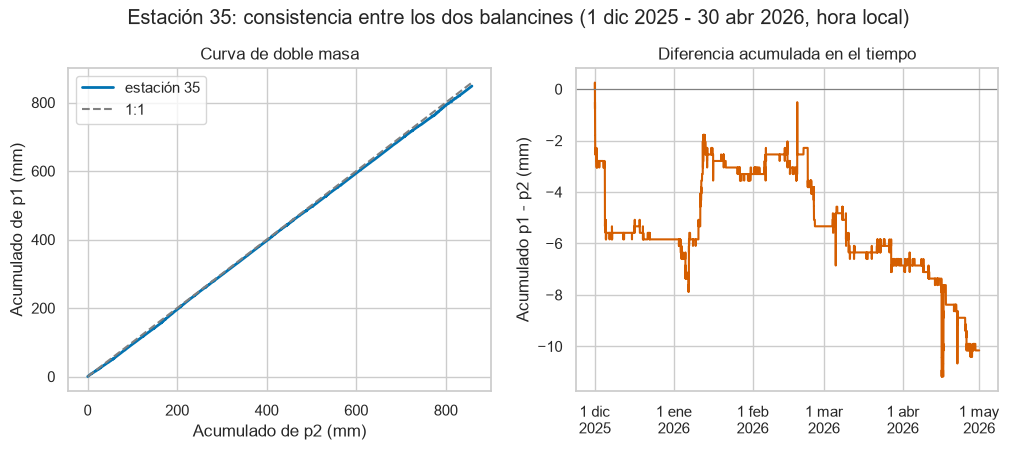

total p1 = 848.106 mm, p2 = 858.266 mm, p2 - p1 = 10.160 mm (1.20 % de p1)
                 p1       p2  p1/p2  p1-p2
fecha_hora                                
2025-12-01  109.220  115.062  0.949 -5.842
2026-01-01  247.396  244.856  1.010  2.540
2026-02-01  141.478  143.510  0.986 -2.032
2026-03-01  151.130  152.654  0.990 -1.524
2026-04-01  198.882  202.184  0.984 -3.302

días con mayor |p1 - p2| (mm): {Timestamp('2025-12-01 00:00:00'): 2.794, Timestamp('2025-12-04 00:00:00'): 2.286, Timestamp('2026-01-11 00:00:00'): 1.778, Timestamp('2026-02-22 00:00:00'): 1.524, Timestamp('2026-01-12 00:00:00'): 1.524}


In [23]:
c = p.fillna(0).cumsum()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(c.p2, c.p1, color=COL[0], lw=2, label="estación 35")
lim = c.max().max()
ax[0].plot([0, lim], [0, lim], "--", color="gray", label="1:1")
ax[0].set_xlabel("Acumulado de p2 (mm)")
ax[0].set_ylabel("Acumulado de p1 (mm)")
ax[0].set_title("Curva de doble masa")
ax[0].legend()
ax[1].plot(c.index, c.p1 - c.p2, color=COL[3], lw=1.5)
ax[1].axhline(0, color="gray", lw=0.8)
ax[1].set_ylabel("Acumulado p1 - p2 (mm)")
ax[1].set_title("Diferencia acumulada en el tiempo")
fecha_es(ax[1])
fig.suptitle(f"Estación 35: consistencia entre los dos balancines ({PERIODO})", y=1.02)
guardar(fig, "p1_vs_p2")
plt.show()
tot = p.sum()
print(f"total p1 = {tot.p1:.3f} mm, p2 = {tot.p2:.3f} mm, p2 - p1 = {tot.p2 - tot.p1:.3f} mm ({100 * (tot.p2 - tot.p1) / tot.p1:.2f} % de p1)")
mes_p = D.resample("MS").sum()
mes_p["p1/p2"] = mes_p.p1 / mes_p.p2
mes_p["p1-p2"] = mes_p.p1 - mes_p.p2
print(mes_p.round(3).to_string())
dif_dia = (D.p1 - D.p2)
print("\ndías con mayor |p1 - p2| (mm):", dif_dia.abs().nlargest(5).round(3).to_dict())

¿Las diferencias minuto a minuto son errores o un desfase de una vuelta que se cancela al agregar?

        periodos con lluvia  iguales (%)  difieren 1 vuelta o menos (%)  correlación  |dif| media (mm)
1 min                3119.0       33.601                         99.647        0.714             0.173
10 min                934.0       44.433                         97.216        0.992             0.151
1 h                   356.0       46.067                         91.011        0.998             0.187
1 día                  96.0       40.625                         76.042        0.999             0.323 

correlación minutal de p1 con p2 desplazado k minutos: {-3: np.float64(0.648), -2: np.float64(0.704), -1: np.float64(0.784), 0: np.float64(0.843), 1: np.float64(0.791), 2: np.float64(0.703), 3: np.float64(0.645)}


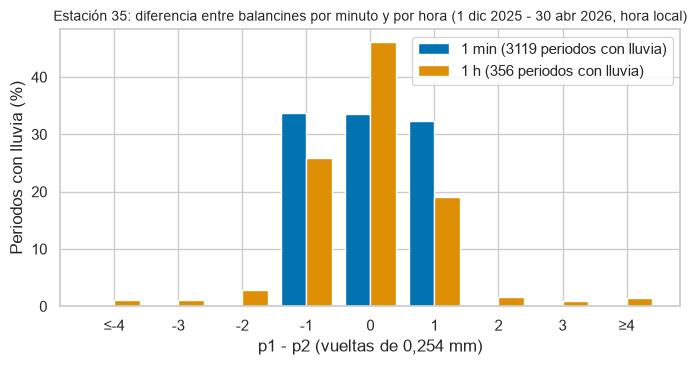

In [24]:
filas = {}
for nombre, f in [("1 min", "min"), ("10 min", "10min"), ("1 h", "h"), ("1 día", "D")]:
    a = p.resample(f).sum()
    w = (a > 0).any(axis=1)
    dv = ((a.p1 - a.p2)[w] / VUELTA).round()
    filas[nombre] = {"periodos con lluvia": int(w.sum()), "iguales (%)": 100 * (dv == 0).mean(),
                     "difieren 1 vuelta o menos (%)": 100 * (dv.abs() <= 1).mean(),
                     "correlación": a.p1[w].corr(a.p2[w]), "|dif| media (mm)": (a.p1 - a.p2)[w].abs().mean()}
escalas = pd.DataFrame(filas).T
print(escalas.round(3).to_string(), "\n")
print("correlación minutal de p1 con p2 desplazado k minutos:",
      {k: round(p.p1.corr(p.p2.shift(k)), 3) for k in range(-3, 4)})

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, (nombre, f) in enumerate([("1 min", "min"), ("1 h", "h")]):
    a = p.resample(f).sum()
    w = (a > 0).any(axis=1)
    dv = ((a.p1 - a.p2)[w] / VUELTA).round().clip(-4, 4).value_counts(normalize=True).reindex(range(-4, 5), fill_value=0)
    ax.bar(dv.index + (i - 0.5) * 0.4, 100 * dv, width=0.4, color=COL[i], label=f"{nombre} ({w.sum()} periodos con lluvia)")
ax.set_xticks(range(-4, 5), ["≤-4", "-3", "-2", "-1", "0", "1", "2", "3", "≥4"])
ax.set_xlabel("p1 - p2 (vueltas de 0,254 mm)")
ax.set_ylabel("Periodos con lluvia (%)")
ax.set_title(f"Estación 35: diferencia entre balancines por minuto y por hora ({PERIODO})", fontsize=10)
ax.legend()
plt.show()

El balancín p2 registró 10,16 mm más que p1 en el periodo (858,27 frente a 848,11 mm, 1,20 % de p1). La curva de doble
masa es casi la recta 1:1 y no muestra quiebres. La diferencia no es una deriva estable: 5,84 mm se acumulan en
diciembre (cociente p1/p2 de 0,949), sobre todo el 1 dic (2,79 mm) y el 4 dic (2,29 mm); en enero p1 registra más que
p2 (cociente 1,010) y de febrero a abril el cociente queda entre 0,984 y 0,990. La diferencia acumulada se mueve a
saltos en días de tormenta, sin una pendiente sostenida. Los dos balancines son consistentes en el total; p2 tiene algo
más de lluvia, pero no de forma tan estable como para corregir uno con el otro.

Minuto a minuto solo coinciden en el 33,6 % de los minutos con lluvia, pero el 99,6 % difiere en una vuelta o menos y
la diferencia es simétrica (p1 va adelante tan seguido como p2). Es el desfase de una vuelta: cada balancín gira cuando
se llena y el agua que le quedó del giro anterior es distinta, así que la misma vuelta cae en minutos distintos.
WMO-No. 8 (2023), Vol. I, 6.5.2.2 (h), describe este error de muestreo del balancín. Al agregar se cancela: la
correlación pasa de 0,714 en los minutos con lluvia a 0,992 en 10 min y 0,998 por hora. La correlación con desfase es
máxima en 0 (0,843) y simétrica, así que no hay un reloj corrido entre los dos. Comparar p1 y p2 minuto a minuto
daría falsas alarmas; la comparación debe hacerse en 10 min o más.

### Ráfagas de 8 vueltas con el sitio seco

¿Hay minutos de lluvia intensa en la 35 que la 367, en el mismo sitio, no ve? Se buscan minutos con 7
vueltas o más en un balancín mientras la 367 registra menos de 1 mm en ±30 min. En tormentas reales con esa
intensidad la 367 registra varios milímetros (ver la tabla siguiente, columna `p367_±30min_mm`).

In [25]:
p35_30 = lluvia.fillna(0).rolling("61min", center=True).sum()
tabla_f = p[fuerte].assign(calidad=cod[fuerte], p35_media_30min_mm=p35_30[fuerte], p367_30min_mm=p367_30[fuerte])
tabla_f = tabla_f.rename(columns={"p35_media_30min_mm": "p35_±30min_mm", "p367_30min_mm": "p367_±30min_mm"})
print(tabla_f.round(3).to_string())

                        p1     p2  calidad  p35_±30min_mm  p367_±30min_mm
fecha_hora                                                               
2025-12-16 10:51:00  2.032  1.778      251          2.032            0.01
2026-01-16 11:10:00  2.032  1.016      151          2.159            0.00
2026-02-18 12:27:00  2.032  0.000     1511          2.667            0.00
2026-02-18 12:28:00  0.000  2.032     1512          2.667            0.00
2026-03-05 14:01:00  1.524  1.778        1         19.685            4.46
2026-03-05 14:02:00  1.778  2.032        1         19.685            4.46
2026-03-05 14:08:00  2.032  2.032        1         19.685            4.50
2026-03-05 14:11:00  1.524  1.778        1         19.685            4.52
2026-03-05 15:20:00  0.000  2.032     1512          2.667            0.61
2026-03-05 15:21:00  2.032  0.000     1511          2.667            0.60
2026-03-27 10:05:00  1.778  2.032        1         26.924            5.91
2026-03-27 10:06:00  1.778  1.778     

In [26]:
rafaga = fuerte & (p367_30 < 1.0)
# minutos de ráfaga a menos de 5 min entre sí son un mismo episodio
t = rafaga.index[rafaga].to_series()
episodio = (t.diff() > pd.Timedelta("5min")).cumsum()
filas = []
for _, g in t.groupby(episodio):
    a, b = g.iloc[0] - pd.Timedelta("2min"), g.iloc[-1] + pd.Timedelta("2min")
    v30 = slice(g.iloc[0] - pd.Timedelta("30min"), g.iloc[-1] + pd.Timedelta("30min"))
    filas.append({"pico": g.iloc[0], "dia": DIAS[g.iloc[0].day_of_week], "p1_pico±2min_mm": p.p1.loc[a:b].sum(),
                  "p2_pico±2min_mm": p.p2.loc[a:b].sum(), "p1_±30min_mm": p.p1.loc[v30].sum(), "p2_±30min_mm": p.p2.loc[v30].sum(),
                  "p367_±30min_mm": m367.p.loc[v30].sum(), "codigos": sorted(cod.loc[v30][cod.loc[v30] != 1].unique().tolist())})
episodios = pd.DataFrame(filas)
episodios.round(3)

,pico,dia,p1_pico±2min_mm,p2_pico±2min_mm,p1_±30min_mm,p2_±30min_mm,p367_±30min_mm,codigos
0,2025-12-16 10:51:00,mar,2.032,2.032,2.032,2.032,0.01,"[2, 251, 2512]"
1,2026-01-16 11:10:00,vie,2.032,2.032,2.032,2.286,0.00,"[151, 1512]"
2,2026-02-18 12:27:00,mié,2.032,2.032,3.048,2.286,0.00,"[151, 1511, 1512]"
3,2026-03-05 15:20:00,jue,2.032,2.032,3.048,2.286,0.61,"[1511, 1512]"
4,2026-04-22 10:38:00,mié,2.032,2.286,2.286,2.540,0.10,"[1511, 1512]"


¿Cómo se ven esos episodios minuto a minuto?

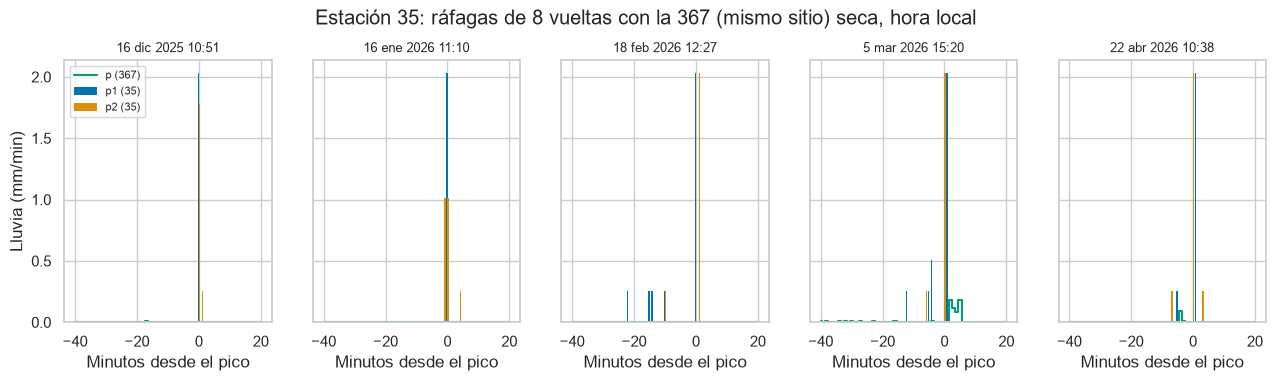

lluvia en las ventanas de ±30 min: p1 = 12.446 mm, p2 = 11.430 mm (1.47 % y 1.33 % del total)
calidad de SIATA y banderas propias en los minutos de ráfaga (4 vueltas o más):
                        p1     p2  calidad  b_p1  b_p2
fecha_hora                                            
2025-12-16 10:51:00  2.032  1.778      251     1     1
2026-01-16 11:09:00  0.000  1.016     1512     1     1
2026-01-16 11:10:00  2.032  1.016      151     1     1
2026-02-18 12:27:00  2.032  0.000     1511     3     1
2026-02-18 12:28:00  0.000  2.032     1512     1     3
2026-03-05 15:20:00  0.000  2.032     1512     1     3
2026-03-05 15:21:00  2.032  0.000     1511     3     1
2026-04-22 10:38:00  0.000  2.032     1512     1     1
2026-04-22 10:39:00  2.032  0.000     1511     1     1
minutos con 8 vueltas: p1 10 p2 8 | fuera de las ventanas: p1 5 p2 5
minutos de la 367 que el control propio marca 'lluvia_no_registrada' dentro de las ventanas, por día: {'2026-01-16': 41, '2026-02-18': 58}
367 con códig

In [27]:
fig, axs = plt.subplots(1, len(episodios), figsize=(3.1 * len(episodios), 3.4), sharey=True)
for ax, (_, e) in zip(np.atleast_1d(axs), episodios.iterrows()):
    v = slice(e.pico - pd.Timedelta("40min"), e.pico + pd.Timedelta("20min"))
    x = (p.loc[v].index - e.pico) / pd.Timedelta("1min")
    ax.bar(x - 0.2, p.p1.loc[v], width=0.45, color=COL[0], linewidth=0, label="p1 (35)")
    ax.bar(x + 0.2, p.p2.loc[v], width=0.45, color=COL[1], linewidth=0, label="p2 (35)")
    ax.step(x, m367.p.loc[v], where="mid", color=COL[2], lw=1.5, label="p (367)")
    ax.set_title(f"{e.pico.day} {MESES[e.pico.month]} {e.pico.year} {e.pico:%H:%M}", fontsize=9)
    ax.set_xlabel("Minutos desde el pico")
np.atleast_1d(axs)[0].set_ylabel("Lluvia (mm/min)")
np.atleast_1d(axs)[0].legend(fontsize=8)
fig.suptitle("Estación 35: ráfagas de 8 vueltas con la 367 (mismo sitio) seca, hora local", y=1.03)
guardar(fig, "rafagas_8_vueltas")
plt.show()
ventanas = pd.Series(False, index=m.index)
for _, e in episodios.iterrows():
    ventanas.loc[e.pico - pd.Timedelta("30min"): e.pico + pd.Timedelta("30min")] = True
print(f"lluvia en las ventanas de ±30 min: p1 = {p.p1[ventanas].sum():.3f} mm, p2 = {p.p2[ventanas].sum():.3f} mm "
      f"({100 * p.p1[ventanas].sum() / p.p1.sum():.2f} % y {100 * p.p2[ventanas].sum() / p.p2.sum():.2f} % del total)")
print("calidad de SIATA y banderas propias en los minutos de ráfaga (4 vueltas o más):")
en_rafaga = ventanas & (p.max(axis=1) >= 4 * VUELTA - 1e-9)
print(m.loc[en_rafaga, ["p1", "p2", "calidad", "b_p1", "b_p2"]].to_string())
ocho = (p / VUELTA).round() == 8
print("minutos con 8 vueltas: p1", int(ocho.p1.sum()), "p2", int(ocho.p2.sum()), "| fuera de las ventanas: p1",
      int((ocho.p1 & ~ventanas).sum()), "p2", int((ocho.p2 & ~ventanas).sum()))
fallas = pd.read_parquet(DIR_SALIDAS / "fallas.parquet")
f367 = fallas[(fallas.codigo == "367") & (fallas.prueba == "lluvia_no_registrada")].set_index("fecha_hora")
en_v = ventanas.reindex(f367.index, fill_value=False)
print("minutos de la 367 que el control propio marca 'lluvia_no_registrada' dentro de las ventanas, por día:",
      {str(k): int(v) for k, v in en_v.groupby(en_v.index.date).sum().items() if v > 0})
print("367 con código 1567 (viento en cero) el 5 mar 2026:", m367.loc["2026-03-05"].index[m367.loc["2026-03-05", "calidad"] == 1567][[0, -1]].tolist())
print("eventos que contienen un episodio:")
ev_ep = ev[[any((e >= a) & (e <= b) for e in episodios.pico) for a, b in zip(ev.inicio, ev.fin)]]
print(ev_ep.round(2).to_string())

Hay 5 episodios con la misma firma: cada balancín registra exactamente 8 vueltas (2,032 mm) en uno o dos
minutos seguidos, mientras la 367, en el mismo sitio, registra entre 0 y 0,61 mm en ±30 min. En las tormentas reales
con esa intensidad la 367 registra entre 1,58 y 10,6 mm. Los episodios son el 16 dic 2025, 16 ene, 18 feb, 5 mar y
22 abr 2026, todos en día hábil, entre las 10:38 y las 15:21, más o menos uno por mes. Varios traen vueltas sueltas en
los minutos previos.

Lo más probable (inferido) es que sean pruebas de mantenimiento o verificaciones de campo (pasar un volumen conocido de agua por el embudo,
como recomienda WMO-No. 8 (2023), Vol. I, 6.5.2.3) que quedaron registradas como lluvia. Hay evidencia cruzada: el
5 mar la 367 tiene código 1567 (velocidad y dirección del viento dudosas) en varios tramos entre las 14:49 y las 18:21, la mayoría de 16:29 a 17:17, compatible con una visita al sitio, y registra
0,61 mm en ±30 min, casi todo en los minutos que siguen a la ráfaga; el 16 dic la ráfaga cierra el periodo con código 2. Para confirmarlo hace falta la
bitácora de mantenimiento de SIATA.

En los totales pesan poco (12,4 mm en p1 y 11,4 mm en p2 en las ventanas de ±30 min, 1,47 % y 1,33 % del total), pero
cada ráfaga equivale a 121,9 mm/h en un minuto, una intensidad de alerta, y crea 4 eventos falsos con el sitio seco. SIATA
pone un código distinto de 1 en todos los minutos de ráfaga (151, 251, 1511 o 1512), pero esos códigos dicen "dudoso"
o "un solo balancín", no "prueba", y el dato se publica. El control propio solo marca 2 de los 5 episodios (18 feb y
5 mar, por la regla horaria de desacuerdo) y deja los otros 3 como buenos. Además, la regla espacial del control propio
(`lluvia_no_registrada`) culpa a la 367, que estaba bien: marca 41 de sus minutos el 16 ene y 58 el 18 feb dentro de
las ventanas.

### El periodo con código 2 (14 a 16 dic 2025)

¿Qué pasó entre el 14 y el 16 de diciembre?

In [28]:
print(rachas(tarde).to_string(), "\n")
v = tarde
print("lluvia en minutos con código 2xx:", p[v].sum().round(3).to_dict())
print("completitud de filas del 14 al 16 dic:", round(100 * m.loc["2025-12-14":"2025-12-16", "presente"].mean(), 1), "%")
print("\núltimos minutos del periodo con código 2xx:")
print(m.loc["2025-12-16 10:48":"2025-12-16 10:54", ["p1", "p2", "calidad"]].to_string())

               inicio                 fin  minutos
0 2025-12-14 09:37:00 2025-12-16 10:40:00     2944
1 2025-12-16 10:51:00 2025-12-16 10:52:00        2 

lluvia en minutos con código 2xx: {'p1': 3.048, 'p2': 3.048}
completitud de filas del 14 al 16 dic: 100.0 %

últimos minutos del periodo con código 2xx:
                        p1     p2  calidad
fecha_hora                                
2025-12-16 10:48:00  0.000  0.000        1
2025-12-16 10:49:00  0.000  0.000        1
2025-12-16 10:50:00  0.000  0.000        1
2025-12-16 10:51:00  2.032  1.778      251
2025-12-16 10:52:00  0.000  0.254     2512
2025-12-16 10:53:00  0.000  0.000        1
2025-12-16 10:54:00  0.000  0.000        1


Del 14 dic 2025 a las 09:37 al 16 dic a las 10:40 todos los minutos tienen código 2 (2944 minutos, 49 h);
siguen 10 minutos con código 1 y luego la ráfaga de 8 vueltas de las 10:51 y 10:52, con 251 y 2512. La completitud de
filas de esos tres días es 100 %, así que un indicador de completitud no ve nada. La lectura más simple (inferida) es
una falla de transmisión: el registrador guardó los datos y se descargaron después, probablemente en la visita del
16 dic en la que también se hizo la prueba de los balancines. En esas 49 h hubo poca lluvia (1,016 mm por balancín; los minutos con código 2xx suman
3,048 mm porque incluyen los 2,032 mm de la ráfaga), así que no se perdió un evento importante; en una semana lluviosa, la misma falla dejaría
a la red sin este pluviómetro durante una tormenta.

### Efecto del control propio sobre la serie horaria del pipeline

La serie horaria `horario.parquet` suma solo los minutos con bandera buena (en p1 y p2, también los sospechosos). ¿Cuánta lluvia conserva frente a
la suma directa?

In [29]:
hc = pd.DataFrame({v: agregar(m[v], v, "h", 0.9) for v in ["p1", "p2"]})
hp = horario[["35_p1", "35_p2"]].reindex(hc.index).set_axis(["p1", "p2"], axis=1)
nan_h = hp.p1.isna()
print("total directo (mm):", hc.sum().round(2).to_dict(), "| total en horario.parquet:", hp.sum().round(2).to_dict())
print(f"horas en NaN en horario.parquet: {nan_h.sum()}, con {hc.p1[nan_h].sum():.1f} mm de p1 "
      f"({100 * hc.p1[nan_h].sum() / hc.p1.sum():.1f} % del total) y {hc.p2[nan_h].sum():.1f} mm de p2")
print("horas con lluvia en el periodo:", int(moja_h.sum()), "| de las 10 horas más lluviosas, en NaN:", int(nan_h[hc.mean(axis=1).nlargest(10).index].sum()))
perd = hc[nan_h].assign(dif_mm=lambda x: x.p1 - x.p2, dif_vueltas=lambda x: ((x.p1 - x.p2) / VUELTA).round(),
                        dif_relativa_pct=lambda x: 100 * (x.p1 - x.p2).abs() / ((x.p1 + x.p2) / 2))
print(perd.round(3).to_string())
dos = perd[perd.dif_vueltas.abs() == 2]
print("\nhoras en NaN con diferencia de exactamente 2 vueltas:", len(dos), "| |p1 - p2| - 0.508 en esas horas:",
      [f"{x:.1e}" for x in (dos.p1 - dos.p2).abs() - 0.508])
print(f"diferencia relativa en las horas en NaN: mediana {perd.dif_relativa_pct.median():.1f} %, máxima {perd.dif_relativa_pct.max():.1f} %")
print(f"con un umbral de más de 2 vueltas Y más del 10 % seguirían marcadas: {int(((perd.dif_vueltas.abs() > 2) & (perd.dif_relativa_pct > 10)).sum())} de {len(perd)}")
cero = (hp.p1 == 0) & (hc.p1 > 0)
print("horas que quedan en 0 mm en horario.parquet aunque llovió:", hc[cero].round(3).to_dict("index"))

total directo (mm): {'p1': 848.11, 'p2': 858.27} | total en horario.parquet: {'p1': 848.11, 'p2': 858.27}
horas en NaN en horario.parquet: 0, con 0.0 mm de p1 (0.0 % del total) y 0.0 mm de p2
horas con lluvia en el periodo: 356 | de las 10 horas más lluviosas, en NaN: 0
Empty DataFrame
Columns: [p1, p2, dif_mm, dif_vueltas, dif_relativa_pct]
Index: []

horas en NaN con diferencia de exactamente 2 vueltas: 0 | |p1 - p2| - 0.508 en esas horas: []
diferencia relativa en las horas en NaN: mediana nan %, máxima nan %
con un umbral de más de 2 vueltas Y más del 10 % seguirían marcadas: 0 de 0
horas que quedan en 0 mm en horario.parquet aunque llovió: {}


Este hallazgo era del pipeline del propio repositorio y ya lo corregí. La regla `p1_p2_difieren` de
`calidad.py` marcaba con bandera 3 todos los minutos con lluvia de una hora en que p1 y p2 diferían en más de 0,508
mm, y el agregado horario, que solo usaba minutos buenos, dejaba esas horas en NaN o en 0 mm: justo las de tormenta,
porque la diferencia entre balancines crece con la intensidad.

Cambié dos cosas: la regla ahora exige que la diferencia pase de dos vueltas y también del 10 % de la lluvia de
la hora, y `pipeline.py` suma en la serie horaria de p1 y p2 los minutos sospechosos (el desacuerdo marca la hora, no
la borra). Con eso `horario.parquet` conserva 848,11 mm de p1 y 858,27 mm de p2, igual que la suma directa, y ninguna
hora queda en NaN ni en 0 mm por el control.

Queda pendiente una prueba automática que compare la suma de `horario.parquet` con la suma directa, para que esto no
vuelva a pasar sin aviso.

## A6. Hallazgos priorizados

Prioridad por impacto en la alerta y en los productos que salen de esta estación.

| Prioridad | Problema | Evidencia | Impacto | Recomendación |
|---|---|---|---|---|
| 1 Resuelto | La serie horaria del pipeline borraba las horas de tormenta | Corregido en `calidad.py` (umbral relativo) y `pipeline.py` (la hora conserva los minutos sospechosos): `horario.parquet` suma 848,11 mm de p1, igual que la suma directa, y ninguna hora queda en NaN | Ninguno con la versión actual | Agregar una prueba automática que compare la suma horaria con la directa |
| 2 Alta | Ráfagas de 8 vueltas con el sitio seco, compatibles con pruebas de mantenimiento (inferido) | 5 episodios, cada balancín 2,032 mm en 1 o 2 min, la 367 entre 0 y 0,61 mm en ±30 min; días hábiles de 10:38 a 15:21 | 121,9 mm/h aparentes (falsa alerta), 4 eventos falsos, 12,4 mm en p1 (1,47 %); el control propio deja 3 de 5 como buenos y marca por error a la 367 (41 y 58 minutos) | Pedir la bitácora de mantenimiento; regla automática: 7 vueltas o más en un minuto con la 367 seca, bandera 3 y fuera de las intensidades |
| 3 Alta | La completitud del 100 % esconde una falla de transmisión | 2944 minutos con código 2 del 14 dic 09:37 al 16 dic 10:40 (49 h); completitud por filas 100 % (99,997 % con valor), en tiempo real 98,64 % | 49 h sin el pluviómetro para la alerta, sin que ningún indicador por filas lo muestre | Medir la completitud en tiempo real (por latencia de llegada) aparte de la histórica y alertar cuando una estación deje de reportar |
| 4 Media | `calidad` de SIATA no sirve como único filtro | kappa 0,068 frente al control propio; 1511 y 1512 marcan solo el 4,9 % y el 6,0 % de los minutos con un solo balancín; el 88,1 % de lo marcado dudoso pasa el control propio | Filtrar por `calidad` deja pasar las ráfagas y no cubre los desacuerdos horarios | Publicar el diccionario de códigos junto con los datos (hoy está en la guía de la red); combinar `calidad` con el control propio |
| 5 Media | Diferencia entre balancines no estable | p2 - p1 = 10,16 mm (1,20 %), 5,84 mm en diciembre (cociente 0,949), después entre 0,984 y 1,010 | Incertidumbre de 1 a 2 % en totales y mayor en algunas horas | Publicar la media de los dos; verificación de campo periódica (WMO-No. 8, 6.5.2.3); vigilar la diferencia acumulada |
| 6 Baja | Desfase de una vuelta minuto a minuto | 33,6 % de minutos con lluvia iguales, 99,6 % a una vuelta o menos; correlación 0,714 por minuto y 0,998 por hora | Una regla minutal entre balancines daría falsas alarmas | Comparar en ventanas de 10 min o más |
| 7 Baja | 7 centinelas -999 | 8 ene (6) y 25 mar (1), en los dos sensores, código 151, sin lluvia en ±30 min | Ninguno en los totales; imputar cero borraría la falla | Dejar en NaN con bandera 9, como hacen `regularizar` (NaN) y `calidad.evaluar` (bandera 9) |
| 8 Para la Tarea B | Lluvia intermitente y concentrada | 1,43 % de minutos y 9,82 % de horas con lluvia; la mitad del total en el 0,26 % del periodo; 38,4 % del total entre 14 y 16 h | Un modelo continuo de la serie horaria tiende a predecir casi siempre cero | Modelo de dos partes (ocurrencia y cantidad) y un modelo ingenuo de referencia por hora del día |